# Tien herhaalde opwarmmetingen: supergeleider, offsetcompensatie en B–T

Deze notebook verwerkt **10 doorlopende runs**. Elke run bestaat uit één DMM-bestand (PT1000-weerstand) en één SMU-bestand (spanning). Per run verandert de stroom in deze volgorde:

`+0.1 → −0.1 → +0.3 → −0.3 → +0.5 → −0.5 → +0.7 → −0.7 A`

De analyse:
1. leest de ene numerieke kolom uit elk bestand;
2. rekent PT1000-weerstand om naar temperatuur met jullie kalibratie;
3. deelt iedere run op in stroomblokken;
4. zoekt positieve en negatieve stroommetingen **bij dezelfde temperatuur** op temperatuur-bin niveau;
5. berekent offsetgecorrigeerde weerstandscurves en spreiding over runs;
6. schat eventueel per stroom de overgangstemperatuur en maakt een verkennende B–T-plot.

**Belangrijke beperking van de exports:** de getoonde bestanden hebben geen tijdstempels. De code koppelt DMM en SMU daarom op meetindex. Dat is alleen verantwoord als beide instrumenten synchroon gestart zijn en dezelfde samplecadans hebben. Ook moeten de meetindexen van de stroomwisselingen kloppen.

De offsetcompensatie gebruikt de practicumformule
\[
V_{\mathrm{sample}}(T)=\frac{V(+I,T)-V(-I,T)}{2},\qquad R(T)=\frac{V(+I,T)-V(-I,T)}{2I}.
\]
De positieve en negatieve metingen worden niet blind op relatieve voortgang gekoppeld, maar alleen in dezelfde temperatuur-bin **binnen dezelfde run**. Zo voorkomen we dat een temperatuurstijging tussen stroomblokken ongemerkt als offset wordt behandeld. Als er weinig overlap is, zal de notebook dat melden in plaats van data te extrapoleren.

## 1. Instellingen invullen

Pas vooral de bestandsnaam-template aan de echte SMU-bestandsnamen aan. Als jullie bestandsnamen anders zijn, kun je in `RUN_FILES` ieder pad afzonderlijk invullen.

`CURRENT_STEP_START_INDEX_COMMON` bevat de 0-based index waarop ieder stroomblok begint. De eerste startindex is altijd 0. Als de blokgrenzen per run verschillen, vul dan `CURRENT_STEP_START_INDEX_BY_RUN` in voor die runs; deze instellingen overschrijven de gemeenschappelijke lijst.

Bijvoorbeeld, `[0, 72, 143, ...]` is alleen een voorbeeldvorm, **geen echte meetgrens**. Gebruik de werkelijke waarden uit jullie meetprogramma/logboek.

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ---------- BESTANDEN ----------
RUN_NUMBERS = list(range(1, 11))  # Runs 1 t/m 5 (of 1 t/m 10)
DMM_FILE_TEMPLATE = "DMMdataW3_{run}_out.csv"
SMU_FILE_TEMPLATE = "SMUdataW3_{run}_out.csv"

DMM_SKIPROWS = 5
SMU_SKIPROWS = 7

# ---------- PT1000-KALIBRATIE ----------
R_77 = 197.5    # Weerstand bij vloeibare stikstof (77 K)
R_293 = 1078.0  # Weerstand bij kamertemperatuur (293 K)

PT1000_a = (293 - 77) / (R_293 - R_77)
PT1000_b = 77 - (PT1000_a * R_77)

# ---------- SMU KOLOMKOPPELING (+I en -I) ----------
# (stroomsterkte in A, kolom-index positief, kolom-index negatief)
CURRENT_PAIRS = [
    (0.1, 0, 1),  # Kolom 0 = +0.1A, Kolom 1 = -0.1A
    (0.3, 2, 3),  # Kolom 2 = +0.3A, Kolom 3 = -0.3A
    (0.4, 4, 5),  # Kolom 4 = +0.4A, Kolom 5 = -0.4A
    (0.5, 6, 7)   # Kolom 6 = +0.5A, Kolom 7 = -0.5A
]

# ---------- ANALYSE ----------
TC_RESISTANCE_FRACTION = 0.50  # Tc bij 50% van normaaltoestand-weerstand

# ---------- B-ZELFVELD ----------
SAMPLE_WIDTH_M = 0.003      # 3 mm
SAMPLE_THICKNESS_M = 0.002  # 2 mm
SAMPLE_RADIUS_M = (SAMPLE_WIDTH_M + SAMPLE_THICKNESS_M) / np.pi
MU0 = 4 * np.pi * 1e-7

## 2. Bestanden inlezen

De inleesfunctie gebruikt tab als scheidingsteken, slaat de vijf metadataregels over en leest de numerieke kolom. Controleer de gevonden bestandsnamen en meetpunt-aantallen.

In [66]:
def read_data_file(path, skiprows=5):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Bestand niet gevonden: {path}")
    df = pd.read_csv(path, sep="\t", header=None, skiprows=skiprows, engine="python")
    return df

if RUN_FILES is None:
    run_files = [
        {"run": r, "dmm": DMM_FILE_TEMPLATE.format(run=r), "smu": SMU_FILE_TEMPLATE.format(run=r)}
        for r in RUN_NUMBERS
    ]
else:
    run_files = RUN_FILES

print("Geconfigureerde runs:", len(run_files))
for r in run_files:
    print(r)

Geconfigureerde runs: 10
{'run': 1, 'dmm': 'DMMdataW3_1_out.csv', 'smu': 'SMUdataW3_1_out.csv'}
{'run': 2, 'dmm': 'DMMdataW3_2_out.csv', 'smu': 'SMUdataW3_2_out.csv'}
{'run': 3, 'dmm': 'DMMdataW3_3_out.csv', 'smu': 'SMUdataW3_3_out.csv'}
{'run': 4, 'dmm': 'DMMdataW3_4_out.csv', 'smu': 'SMUdataW3_4_out.csv'}
{'run': 5, 'dmm': 'DMMdataW3_5_out.csv', 'smu': 'SMUdataW3_5_out.csv'}
{'run': 6, 'dmm': 'DMMdataW3_6_out.csv', 'smu': 'SMUdataW3_6_out.csv'}
{'run': 7, 'dmm': 'DMMdataW3_7_out.csv', 'smu': 'SMUdataW3_7_out.csv'}
{'run': 8, 'dmm': 'DMMdataW3_8_out.csv', 'smu': 'SMUdataW3_8_out.csv'}
{'run': 9, 'dmm': 'DMMdataW3_9_out.csv', 'smu': 'SMUdataW3_9_out.csv'}
{'run': 10, 'dmm': 'DMMdataW3_10_out.csv', 'smu': 'SMUdataW3_10_out.csv'}


## 3. Runs koppelen en temperatuur berekenen

De DMM- en SMU-data worden per run gekoppeld op meetindex. Als de aantallen verschillen, gebruikt de code alleen het gemeenschappelijke deel en geeft ze een waarschuwing. Controleer of verschil in aantal meetpunten niet op een verkeerde start/cadans wijst.

In [67]:
if not (np.isfinite(PT1000_a) and np.isfinite(PT1000_b)):
    raise ValueError("Vul eerst de PT1000 kalibratiewaarden in.")

all_paired_rows = []
run_length_table = []

for item in run_files:
    run_id = item["run"]
    dmm_df = read_data_file(item["dmm"], skiprows=DMM_SKIPROWS)
    smu_df = read_data_file(item["smu"], skiprows=SMU_SKIPROWS)
    
    r_pt1000 = pd.to_numeric(dmm_df.iloc[:, 0], errors="coerce").dropna().values
    n = min(len(r_pt1000), len(smu_df))
    
    run_length_table.append({"run": run_id, "n_DMM": len(r_pt1000), "n_SMU": len(smu_df), "n_used": n})
    
    temp_K = PT1000_a * r_pt1000[:n] + PT1000_b
    
    for I_abs, col_pos, col_neg in CURRENT_PAIRS:
        v_pos = pd.to_numeric(smu_df.iloc[:n, col_pos], errors="coerce").values
        v_neg = pd.to_numeric(smu_df.iloc[:n, col_neg], errors="coerce").values
        
        v_sample = (v_pos - v_neg) / 2.0
        r_sample = v_sample / I_abs
        
        df_pair = pd.DataFrame({
            "run_id": run_id,
            "sample_index": np.arange(n),
            "R_pt1000_ohm": r_pt1000[:n],
            "temperature_K": temp_K,
            "temperature_C": temp_K - 273.15,
            "current_abs_A": I_abs,
            "V_sample_V": v_sample,
            "R_sample_ohm": r_sample
        })
        all_paired_rows.append(df_pair)

length_table = pd.DataFrame(run_length_table)
display(length_table)

paired = pd.concat(all_paired_rows, ignore_index=True)
data = paired.copy()  # Compatibiliteit met latere cellen
print("Totaal berekende gepaarde punten:", len(paired))
display(paired.head())

,run,n_DMM,n_SMU,n_used
0,1,104,104,104
1,2,76,76,76
2,3,97,97,97
3,4,94,94,94
4,5,113,113,113
5,6,104,104,104
6,7,72,72,72
7,8,69,69,69
8,9,81,81,81
9,10,81,81,81


Totaal berekende gepaarde punten: 3564


,run_id,sample_index,R_pt1000_ohm,temperature_K,temperature_C,current_abs_A,V_sample_V,R_sample_ohm
0,1,0,197.5213,77.005225,-196.144775,0.1,0.000003,0.000032
1,1,1,197.5010,77.000245,-196.149755,0.1,0.000003,0.000031
2,1,2,197.8202,77.078550,-196.071450,0.1,0.000004,0.000036
3,1,3,198.7305,77.301860,-195.848140,0.1,0.000003,0.000034
4,1,4,200.4919,77.733958,-195.416042,0.1,0.000003,0.000027


## 4. Iedere run opdelen in de acht stroomblokken

Vul de echte startindexen van alle stroomstappen in. Als dezelfde meetinstellingen en stapduur in alle runs zijn gebruikt, kun je één gemeenschappelijke lijst gebruiken. Als de overgangen per run verschoven zijn, vul dan de indexen per run in `CURRENT_STEP_START_INDEX_BY_RUN` in.

In [68]:
block_summary = paired.groupby(["run_id", "current_abs_A"], as_index=False).agg(
    n_points=("temperature_K", "count"),
    T_min_K=("temperature_K", "min"),
    T_max_K=("temperature_K", "max")
)
display(block_summary)

,run_id,current_abs_A,n_points,T_min_K,T_max_K
0,1,0.1,104,77.000245,132.203786
1,1,0.3,104,77.000245,132.203786
2,1,0.4,104,77.000245,132.203786
3,1,0.5,104,77.000245,132.203786
4,2,0.1,76,84.145148,126.283129
5,2,0.3,76,84.145148,126.283129
6,2,0.4,76,84.145148,126.283129
7,2,0.5,76,84.145148,126.283129
8,3,0.1,97,76.911171,125.106475
9,3,0.3,97,76.911171,125.106475


## 5. Controleplots van de tien runs

Controleer of de temperatuur tijdens iedere run oploopt en of stroomblokgrenzen goed zijn ingesteld. De stroomplot is een **aangenomen stroomprogramma** op basis van de ingestelde indexen, geen stroommeting uit het bestand.

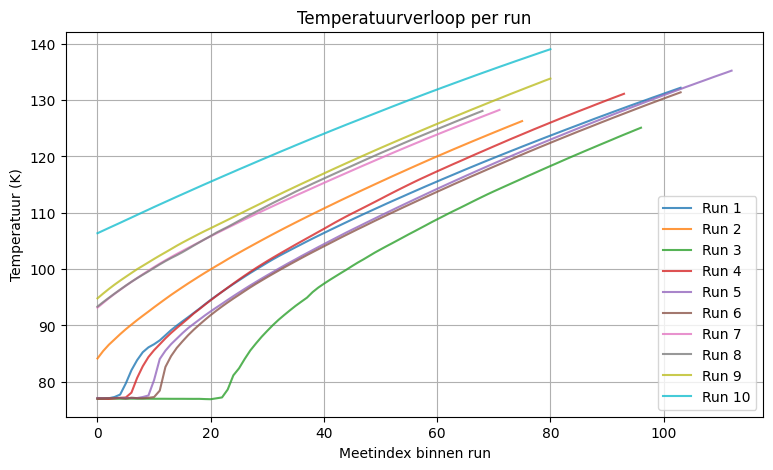

In [69]:
fig, ax = plt.subplots(figsize=(9, 5))
for run_id, g in paired.groupby("run_id"):
    sub = g[g["current_abs_A"] == CURRENT_PAIRS[0][0]]
    ax.plot(sub["sample_index"], sub["temperature_K"], label=f"Run {run_id}", alpha=0.8)

ax.set_xlabel("Meetindex binnen run")
ax.set_ylabel("Temperatuur (K)")
ax.set_title("Temperatuurverloop per run")
ax.grid(True)
ax.legend()
plt.show()

## 6. Offsetcompensatie bij vergelijkbare temperatuur

We maken eerst per run, stroomblok en temperatuur-bin een mediane spanning. Daarna worden `+I` en `−I` **binnen dezelfde run en dezelfde temperatuur-bin** aan elkaar gekoppeld.

- Alleen overlappende temperatuur-bins worden gebruikt; er vindt geen extrapolatie plaats.
- Per gepaard punt geldt \(R=(V_+-V_-)/(2|I|)\).
- Als er weinig overlap is, kunnen sommige stroomgroottes geen betrouwbare offsetgecorrigeerde curve opleveren. Dat is een meetbeperking die je moet rapporteren, geen reden om niet-bestaande punten te verzinnen.

Kies `TEMPERATURE_BIN_WIDTH_K` klein genoeg om de transitie te zien, maar groot genoeg dat er metingen in de bins vallen. Controleer achteraf de aantallen per bin.

In [70]:
paired["T_bin_K"] = (np.floor(paired["temperature_K"] / TEMPERATURE_BIN_WIDTH_K) * TEMPERATURE_BIN_WIDTH_K
                     + TEMPERATURE_BIN_WIDTH_K / 2)

overlap_summary = paired.groupby("current_abs_A").agg(
    n_pairs=("R_sample_ohm", "size"),
    n_runs=("run_id", "nunique"),
    T_min_K=("temperature_K", "min"),
    T_max_K=("temperature_K", "max")
).reset_index()

print("Aantal offsetgecorrigeerde punten per stroomsterkte:")
display(overlap_summary)

Aantal offsetgecorrigeerde punten per stroomsterkte:


,current_abs_A,n_pairs,n_runs,T_min_K,T_max_K
0,0.1,891,10,76.911171,139.039738
1,0.3,891,10,76.911171,139.039738
2,0.4,891,10,76.911171,139.039738
3,0.5,891,10,76.911171,139.039738


## 7. Weerstandscurves en spreiding over runs

De grafiek toont per stroomgrootte de gemiddelde weerstand per temperatuur-bin. De foutbalken tonen één standaarddeviatie tussen de beschikbare runs op die temperatuur-bin; ze zijn niet automatisch de volledige meetonzekerheid.

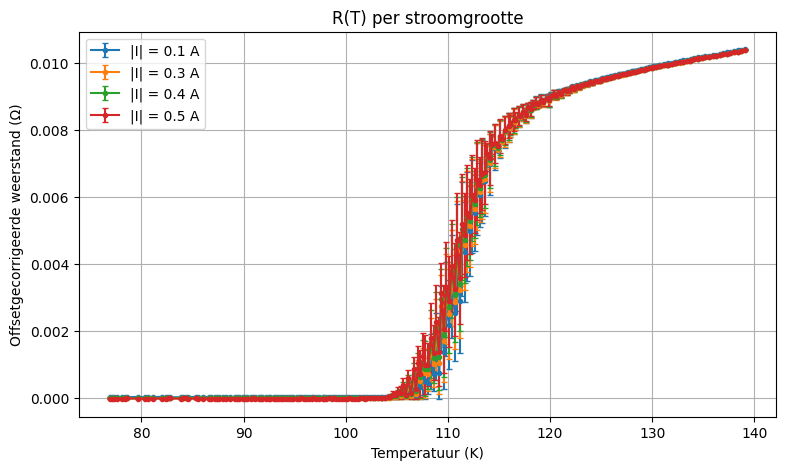

In [71]:
curve_summary = paired.groupby(["current_abs_A", "T_bin_K"], as_index=False).agg(
    temperature_K=("temperature_K", "mean"),
    R_mean_ohm=("R_sample_ohm", "mean"),
    R_std_ohm=("R_sample_ohm", "std"),
    n_runs=("run_id", "nunique")
)

fig, ax = plt.subplots(figsize=(9, 5))
for current, g in curve_summary.groupby("current_abs_A"):
    g = g.sort_values("temperature_K")
    yerr = g["R_std_ohm"].fillna(0)
    ax.errorbar(g["temperature_K"], g["R_mean_ohm"], yerr=yerr, marker="o", markersize=3, linestyle="-",
                capsize=2, label=f"|I| = {current:g} A")

ax.set_xlabel("Temperatuur (K)")
ax.set_ylabel("Offsetgecorrigeerde weerstand (Ω)")
ax.set_title("R(T) per stroomgrootte")
ax.grid(True)
ax.legend()
plt.show()

## 8. Schatting van Tc en vergelijking tussen de tien runs

We definiëren hier \(T_c\) als de temperatuur waarop de weerstand een ingestelde fractie van de normale-toestand-weerstand bereikt (standaard 50%). Dit is een operationele definitie; noem die expliciet in het verslag.

De notebook schat zowel een \(T_c\) uit de gemiddelde curve als een \(T_c\) per individuele run, als die run voldoende gepaarde punten en een duidelijke drempelkruising heeft. De spreiding tussen runs is een maat voor reproduceerbaarheid, niet de enige bron van meetonzekerheid.

In [78]:
import numpy as np
import pandas as pd
from scipy.signal import savgol_filter

def estimate_tc_savgol_direct(group, window_length=15, polyorder=3, T_min_search=95, T_max_search=120):
    """
    Schat Tc via het buigpunt (POI) door direct de 1e afgeleide dR/dT 
    te berekenen met SciPy's Savitzky-Golay filter (deriv=1) 
    in combinatie met parabolische piekinterpolatie.
    """
    g = group.sort_values("temperature_K").dropna(subset=["temperature_K", "R_sample_ohm"]).copy()
    n_points = len(g)
    
    if n_points < 5:
        return np.nan
        
    # Geschikte oneven venstergrootte (window_length) instellen
    wl = min(window_length, n_points if n_points % 2 != 0 else n_points - 1)
    po = min(polyorder, wl - 1)
        
    T = g["temperature_K"].to_numpy()
    R = g["R_sample_ohm"].to_numpy()
    
    dT_mean = np.mean(np.diff(T))
    if dT_mean <= 0:
        return np.nan
        
    # 1. Bereken de 1e afgeleide dR/dT direct analitisch via Savitzky-Golay
    dR_dT = savgol_filter(R, window_length=wl, polyorder=po, deriv=1, delta=dT_mean)
    
    # 2. Selecteer het zoekvenster voor de overgang (bijv. 95 K tot 120 K)
    mask = (T >= T_min_search) & (T <= T_max_search)
    if not np.any(mask):
        mask = np.ones_like(T, dtype=bool)
        
    T_sub = T[mask]
    dR_sub = dR_dT[mask]
    
    # 3. Zoek de piek (het buigpunt) van dR/dT
    max_idx = np.argmax(dR_sub)
    
    # 4. Parabolische piekfitting voor continue sub-grid nauwkeurigheid
    if 0 < max_idx < len(dR_sub) - 1:
        x3 = T_sub[max_idx - 1 : max_idx + 2]
        y3 = dR_sub[max_idx - 1 : max_idx + 2]
        p = np.polyfit(x3, y3, 2)
        if p[0] < 0:  # Controleer of het om een maximum gaat
            tc_val = -p[1] / (2 * p[0])
            if T_sub[max_idx - 1] <= tc_val <= T_sub[max_idx + 1]:
                return float(tc_val)
                
    return float(T_sub[max_idx])

# 1. Bereken Tc met de directe Savitzky-Golay afgeleide per run en per stroomsterkte
tc_rows = []
for (run_id, current), g in paired.groupby(["run_id", "current_abs_A"]):
    tc_k = estimate_tc_savgol_direct(g, window_length=15, polyorder=3, T_min_search=95, T_max_search=120)
    tc_rows.append({
        "run_id": run_id, 
        "current_A": current, 
        "Tc_K": tc_k,
        "Tc_C": tc_k - 273.15 if np.isfinite(tc_k) else np.nan
    })

tc_per_run = pd.DataFrame(tc_rows)

# 2. Samenvattingstabel berekenen
tc_summary = tc_per_run.groupby("current_A", as_index=False).agg(
    n_valid_runs=("Tc_K", "count"), 
    Tc_mean_K=("Tc_K", "mean"), 
    Tc_std_K=("Tc_K", "std"),
    Tc_mean_C=("Tc_C", "mean"), 
    Tc_std_C=("Tc_C", "std")
)

print("Tc (Savitzky-Golay POI) per run:")
display(tc_per_run)
print("\nSamenvatting Tc per stroomsterkte:")
display(tc_summary)

Tc (Savitzky-Golay POI) per run:


,run_id,current_A,Tc_K,Tc_C
0,1,0.1,110.400937,-162.749063
1,1,0.3,110.347681,-162.802319
2,1,0.4,110.273988,-162.876012
3,1,0.5,110.195799,-162.954201
4,2,0.1,109.923813,-163.226187
5,2,0.3,109.857541,-163.292459
6,2,0.4,109.771911,-163.378089
7,2,0.5,109.690138,-163.459862
8,3,0.1,109.539218,-163.610782
9,3,0.3,109.422226,-163.727774



Samenvatting Tc per stroomsterkte:


,current_A,n_valid_runs,Tc_mean_K,Tc_std_K,Tc_mean_C,Tc_std_C
0,0.1,10,110.778156,1.139401,-162.371844,1.139401
1,0.3,10,110.682999,1.145992,-162.467001,1.145992
2,0.4,10,110.595357,1.152052,-162.554643,1.152052
3,0.5,10,110.505556,1.156316,-162.644444,1.156316


## 9. Verkennende B–T-plot

Als eerste geometrische benadering gebruiken we het zelfveld aan het oppervlak van een lange rechte draad:
\[
B=\frac{\mu_0 I}{2\pi r}.
\]
Hier is \(r\) de straal van het **supergeleidermateriaal** in meter. Dit is een geschat zelfveld; het is niet hetzelfde als een direct gemeten extern kritisch veld. De interpretatie van een B–T-plot hangt af van de geometrie van het sample en het soort supergeleider.

,current_A,B_self_T,Tc_mean_K,Tc_std_K,n_valid_runs
0,0.1,0.000013,110.778156,1.139401,10
1,0.3,0.000038,110.682999,1.145992,10
2,0.4,0.000050,110.595357,1.152052,10
3,0.5,0.000063,110.505556,1.156316,10


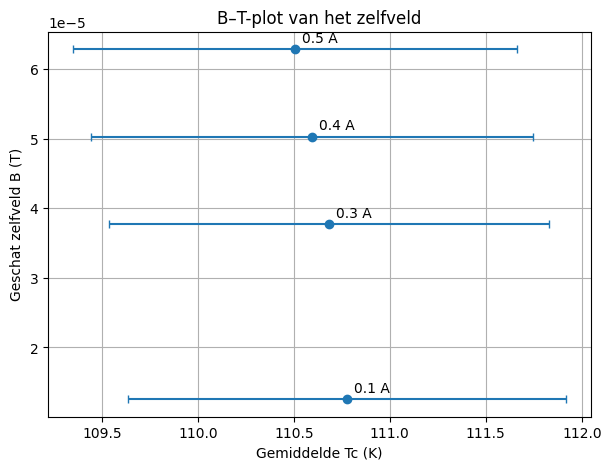

In [79]:
if not np.isfinite(SAMPLE_RADIUS_M) or SAMPLE_RADIUS_M <= 0:
    print("Vul SAMPLE_RADIUS_M in om B te berekenen.")
elif tc_summary.empty:
    print("Geen Tc-samenvatting beschikbaar.")
else:
    bt = tc_summary.dropna(subset=["Tc_mean_K"]).copy()
    bt["B_self_T"] = MU0 * bt["current_A"] / (2 * np.pi * SAMPLE_RADIUS_M)
    display(bt[["current_A", "B_self_T", "Tc_mean_K", "Tc_std_K", "n_valid_runs"]])
    
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.errorbar(bt["Tc_mean_K"], bt["B_self_T"], xerr=bt["Tc_std_K"], marker="o", linestyle="none", capsize=3)
    for _, row in bt.iterrows():
        ax.annotate(f'{row["current_A"]:g} A', (row["Tc_mean_K"], row["B_self_T"]),
                    xytext=(5, 5), textcoords="offset points")
    ax.set_xlabel("Gemiddelde Tc (K)")
    ax.set_ylabel("Geschat zelfveld B (T)")
    ax.set_title("B–T-plot van het zelfveld")
    ax.grid(True)
    plt.show()

## 10. Resultaten opslaan

CSV-uitvoer bevat de gekoppelde ruwe data, stroomblokindeling, offsetgecorrigeerde meetpunten en Tc-tabellen. Gebruik de bestanden pas in het verslag nadat de blokgrenzen, kalibratie en temperatuur-overlap gecontroleerd zijn.

In [74]:
data.to_csv("ten_runs_combined_DMM_SMU.csv", index=False)
block_summary.to_csv("ten_runs_current_blocks.csv", index=False)
per_run_bin.to_csv("ten_runs_voltage_temperature_bins.csv", index=False)
if not paired.empty:
    paired.to_csv("ten_runs_offset_corrected.csv", index=False)
if not tc_per_run.empty:
    tc_per_run.to_csv("ten_runs_Tc_per_run.csv", index=False)
if not tc_summary.empty:
    tc_summary.to_csv("ten_runs_Tc_summary.csv", index=False)
if not tc_curve_table.empty:
    tc_curve_table.to_csv("ten_runs_Tc_from_mean_curves.csv", index=False)
print("CSV-export klaar.")


CSV-export klaar.
